Dataset shape: (400, 9)
  student_id  attendance  previous_score  study_hours  lms_clicks  \
0       S001          91              63          0.0          39   
1       S002          71              69          4.6          48   
2       S003          71              78          7.9          18   
3       S004          85              59          4.3          53   
4       S005          84              73          4.0          16   

   assignment_completion  final_score pass_status dropout_risk  
0                     75         56.0        Fail          Low  
1                     56         64.4        Pass          Low  
2                     69         74.1        Pass       Medium  
3                     95         62.8        Pass          Low  
4                     82         61.9        Pass          Low   

Pass/Fail counts:
 pass_status
Pass    275
Fail    125
Name: count, dtype: int64 

Train: 240  Validation: 80  Test: 80

Logistic Regression test accuracy: 0.812
Early s

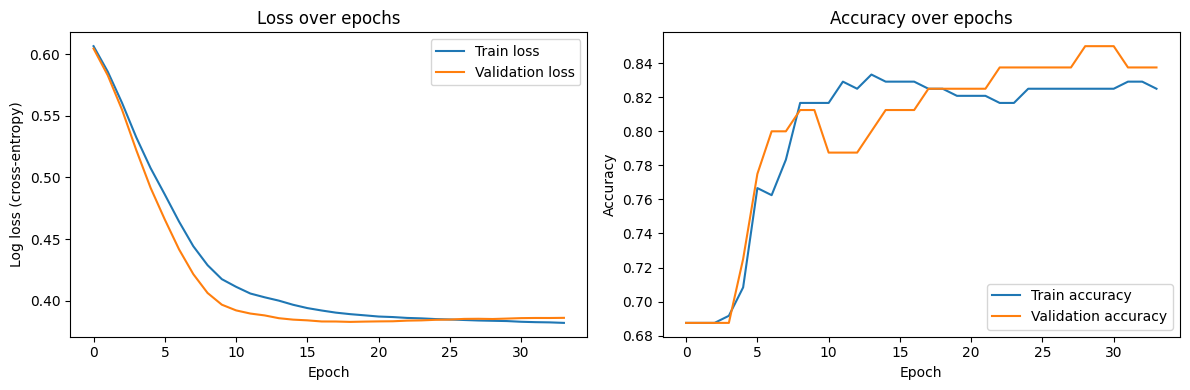

Neural network test accuracy: 0.812

Classification report (neural network):
              precision    recall  f1-score   support

        Fail       0.81      0.52      0.63        25
        Pass       0.81      0.95      0.87        55

    accuracy                           0.81        80
   macro avg       0.81      0.73      0.75        80
weighted avg       0.81      0.81      0.80        80

Confusion matrix (rows = actual, columns = predicted):
[[13 12]
 [ 3 52]]

--- Prediction for the new student ---
Neural network P(Pass):      0.199  ->  Fail
Logistic regression P(Pass): 0.380  ->  Fail

Architecture comparison (validation accuracy):
Logistic regression (no hidden)     0.825
1 hidden layer (8)                  0.838
2 hidden layers (16, 8)             0.825
3 hidden layers (32,16,8)           0.775


In [1]:
# =============================================================
# Practice 1: Predicting Student Pass/Fail with a Neural Network
# INT4096 - AI and Machine Learning in Education
# Dataset: student_data_dropout.csv   |   Library: scikit-learn only
# =============================================================

import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, log_loss,
                             classification_report, confusion_matrix)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# =============================================================
# 1. Load and inspect the dataset
# =============================================================
df = pd.read_csv("/content/sample_data/student_data_dropout.csv")
print("Dataset shape:", df.shape)
print(df.head(), "\n")

# Standardise the target labels to "Pass" / "Fail"
df["pass_status"] = df["pass_status"].astype(str).str.strip().str.capitalize()
print("Pass/Fail counts:\n", df["pass_status"].value_counts(), "\n")

# =============================================================
# 2. Select features and target
#    - final_score is EXCLUDED: it determines pass_status (data leakage)
#    - dropout_risk is EXCLUDED: it is a different target
#    - student_id is EXCLUDED: an identifier, not a feature
# =============================================================
feature_cols = ["attendance", "previous_score", "study_hours",
                "lms_clicks", "assignment_completion"]

df = df.dropna(subset=feature_cols + ["pass_status"])   # basic cleaning
X = df[feature_cols].values.astype(float)
y = (df["pass_status"] == "Pass").astype(int).values    # 1 = Pass, 0 = Fail

# Train / validation / test split (60 / 20 / 20), stratified by class
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=RANDOM_STATE, stratify=y_temp)

# Scale: fit on training data ONLY, then apply to validation and test
scaler = MinMaxScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

print(f"Train: {len(X_train)}  Validation: {len(X_val)}  Test: {len(X_test)}\n")

# =============================================================
# 3. Baseline: Logistic Regression (from the lecture)
# =============================================================
logreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
logreg.fit(X_train_s, y_train)
logreg_acc = accuracy_score(y_test, logreg.predict(X_test_s))
print(f"Logistic Regression test accuracy: {logreg_acc:.3f}")

# =============================================================
# 4. Build the neural network (multilayer perceptron)
#    Input (5) -> Hidden (16, ReLU) -> Hidden (8, ReLU) -> Output (sigmoid)
#    scikit-learn adds the sigmoid output automatically for binary tasks.
# =============================================================
mlp = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    solver="adam",
    learning_rate_init=0.01,
    alpha=1e-4,              # L2 regularisation strength
    batch_size=16,
    random_state=RANDOM_STATE,
)
# =============================================================
# 5. Train epoch by epoch with early stopping on validation loss
#    partial_fit runs ONE epoch per call, so we can record curves
#    and keep the best weights ourselves.
# =============================================================
classes = np.array([0, 1])
max_epochs, patience = 300, 15

train_loss, val_loss = [], []
train_acc,  val_acc  = [], []
best_val_loss, best_model, wait = np.inf, None, 0

for epoch in range(1, max_epochs + 1):
    mlp.partial_fit(X_train_s, y_train, classes=classes)

    p_train = mlp.predict_proba(X_train_s)
    p_val   = mlp.predict_proba(X_val_s)
    train_loss.append(log_loss(y_train, p_train))
    val_loss.append(log_loss(y_val, p_val))
    train_acc.append(accuracy_score(y_train, p_train[:, 1] >= 0.5))
    val_acc.append(accuracy_score(y_val, p_val[:, 1] >= 0.5))

    if val_loss[-1] < best_val_loss - 1e-4:
        best_val_loss = val_loss[-1]
        best_model = copy.deepcopy(mlp)     # keep the best weights so far
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            print(f"Early stopping at epoch {epoch} "
                  f"(best epoch: {epoch - patience})")
            break

mlp = best_model                            # restore the best model
print(f"Neural network trained for {len(train_loss)} epochs\n")

# =============================================================
# 6. Plot learning curves (loss and accuracy)
# =============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(train_loss, label="Train loss")
axes[0].plot(val_loss, label="Validation loss")
axes[0].set_title("Loss over epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Log loss (cross-entropy)")
axes[0].legend()

axes[1].plot(train_acc, label="Train accuracy")
axes[1].plot(val_acc, label="Validation accuracy")
axes[1].set_title("Accuracy over epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.savefig("learning_curves.png", dpi=120)
plt.show()

# =============================================================
# 7. Evaluate on the held-out test set
# =============================================================
nn_pred = mlp.predict(X_test_s)
nn_acc = accuracy_score(y_test, nn_pred)

print(f"Neural network test accuracy: {nn_acc:.3f}")
print("\nClassification report (neural network):")
print(classification_report(y_test, nn_pred, target_names=["Fail", "Pass"]))
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, nn_pred))

# =============================================================
# 8. Predict the "new student" from the lecture
#    Attendance 68, Previous score 55, Study hours 4,
#    LMS clicks 18, Assignments 60
# =============================================================
new_student = np.array([[68, 55, 4, 18, 60]], dtype=float)
new_student_s = scaler.transform(new_student)

nn_prob = mlp.predict_proba(new_student_s)[0, 1]
lr_prob = logreg.predict_proba(new_student_s)[0, 1]

print("\n--- Prediction for the new student ---")
print(f"Neural network P(Pass):      {nn_prob:.3f}  ->  "
      f"{'Pass' if nn_prob >= 0.5 else 'Fail'}")
print(f"Logistic regression P(Pass): {lr_prob:.3f}  ->  "
      f"{'Pass' if lr_prob >= 0.5 else 'Fail'}")

# =============================================================
# 9. Reflection: does adding hidden layers help?
#    Compare several architectures using the SAME validation set.
#    Logistic regression (section 3) is the "no hidden layer" case.
# =============================================================
architectures = {
    "1 hidden layer (8)":        (8,),
    "2 hidden layers (16, 8)":   (16, 8),
    "3 hidden layers (32,16,8)": (32, 16, 8),
}

print("\nArchitecture comparison (validation accuracy):")
print(f"{'Logistic regression (no hidden)':35s} "
      f"{accuracy_score(y_val, logreg.predict(X_val_s)):.3f}")

for name, sizes in architectures.items():
    m = MLPClassifier(hidden_layer_sizes=sizes, activation="relu",
                      solver="adam", learning_rate_init=0.01,
                      alpha=1e-4, batch_size=16, max_iter=500,
                      random_state=RANDOM_STATE)
    m.fit(X_train_s, y_train)
    print(f"{name:35s} {accuracy_score(y_val, m.predict(X_val_s)):.3f}")